# 02 · Limpieza y preprocesamiento del dataset de Falabella

**DS3021 Análisis Computacional de Datos · Proyecto Final, Parte II**

**Objetivo.** Convertir el CSV crudo (`data/raw/falabella_raw.csv`, tal como salió del scraping) en un dataset limpio y confiable, justificando cada decisión. El CSV crudo **no se modifica**: el tratamiento ocurre en memoria y el resultado se guarda en `data/clean/falabella_cleaned.csv`.

La lógica está en [`pipeline/cleaning.py`](../pipeline/cleaning.py), una función por paso, y `pipeline/main.py` la llama con `cleaning.run()`. Este notebook ejecuta esos mismos pasos uno por uno, muestra la evidencia y mide el efecto de cada decisión.

| # | Sección | Tema del curso |
|---|---------|----------------|
| 1 | Diagnóstico del CSV crudo | Calidad de datos |
| 2 | Limpieza: duplicados, texto, accesorios, marcas, faltantes y outliers | Data cleaning |
| 3 | Integración | Data integration |
| 4 | Reducción | Data reduction |
| 5 | Transformación y tipos | Data transformation |
| 6 | Resultado y trazabilidad | Resumen "problema, decisión, justificación, filas afectadas" |

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "pipeline"))

import cleaning as pp

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

CATS = ["laptops", "phones", "tvs"]
FIG = ROOT / "docs" / "img"
FIG.mkdir(parents=True, exist_ok=True)


def say(text):
    display(Markdown(text))


def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")


def soles(x):
    return f"S/ {x:,.0f}"

## 1. Diagnóstico del CSV crudo

Se carga el archivo tal cual y se mide su calidad antes de tocar nada. Cada hallazgo se resuelve en la sección 2.

In [2]:
raw = pp.load_raw()
N_RAW = len(raw)
print(f"Archivo: {pp.RAW_PATH.relative_to(ROOT)}  ->  {raw.shape[0]} filas x {raw.shape[1]} columnas")
display(raw.head())
display(raw.dtypes.rename("tipo").to_frame().T)

Archivo: data\raw\falabella_raw.csv  ->  1680 filas x 7 columnas


,product,brand,category,seller,list_price,internet_price,cmr_price
0,CELULAR REDMI NOTE 17 PRO MAX 5G BLACK + AUDÍFONOS REDMI NEO,XIAOMI,phones,FALABELLA,2199.0,1899.0,1799.0
1,NOTE 17 PRO 5G NEGRO + AUDÍFONOS BLANCOS,XIAOMI,phones,FALABELLA,1799.0,1499.0,1449.0
2,IPHONE 18 PRO MAX 256GB,APPLE,phones,FALABELLA,7299.0,6999.0,6599.0
3,IPHONE 18 PRO 256GB,APPLE,phones,FALABELLA,6699.0,6499.0,5999.0
4,GALAXY S26 FE 128 GB BLACK,SAMSUNG,phones,FALABELLA,3399.0,2899.0,2699.0


,product,brand,category,seller,list_price,internet_price,cmr_price
tipo,str,str,str,str,float64,float64,float64


In [3]:
diag = pd.DataFrame({
    "nulos": raw.isna().sum(),
    "% nulos": (raw.isna().mean() * 100).round(2),
    "valores distintos": raw.nunique(),
})
display(diag)
say(
    f"**Lectura.** Hay dos columnas con vacíos y significan cosas distintas. `list_price` está vacío en "
    f"{raw.list_price.isna().sum()} filas ({raw.list_price.isna().mean():.1%}): es el precio de lista (el tachado) y falta cuando el "
    f"producto no tiene descuento. `cmr_price` está vacío en {raw.cmr_price.isna().sum()} filas ({raw.cmr_price.isna().mean():.1%}): "
    f"el spider solo lo guarda cuando la tarjeta muestra precio exclusivo con CMR, así que un vacío quiere decir \"no hay precio CMR\" "
    f"y no es un dato perdido. El resto de problemas no son nulos sino inconsistencias: filas repetidas, texto sin normalizar "
    f"y productos que no son el equipo de su categoría."
)

,nulos,% nulos,valores distintos
product,0,0.00,1308
brand,0,0.00,95
category,0,0.00,3
seller,0,0.00,305
list_price,74,4.40,405
internet_price,0,0.00,605
cmr_price,1453,86.49,146


**Lectura.** Hay dos columnas con vacíos y significan cosas distintas. `list_price` está vacío en 74 filas (4.4%): es el precio de lista (el tachado) y falta cuando el producto no tiene descuento. `cmr_price` está vacío en 1453 filas (86.5%): el spider solo lo guarda cuando la tarjeta muestra precio exclusivo con CMR, así que un vacío quiere decir "no hay precio CMR" y no es un dato perdido. El resto de problemas no son nulos sino inconsistencias: filas repetidas, texto sin normalizar y productos que no son el equipo de su categoría.

## 2. Limpieza

### 2.1 Duplicados

**Problema.** Filas idénticas en las 7 columnas. El CSV no guarda URL, SKU ni fecha, así que una fila repetida no se puede distinguir de "la misma publicación leída dos veces".

**Decisión.** Eliminar los duplicados exactos y conservar la primera aparición. **Justificación.** Cada publicación debe contar una sola vez; si no, los promedios y conteos de precios quedan sesgados hacia los productos repetidos.

In [4]:
sin_dup, dup_rows = pp.drop_exact_duplicates(raw)
repetidas = (raw.groupby(list(raw.columns), dropna=False).size()
             .sort_values(ascending=False).rename("veces").reset_index())
display(repetidas.head(5))

por_cat = pd.DataFrame({
    "filas crudas": raw.category.value_counts(),
    "duplicados": dup_rows.category.value_counts(),
}).loc[CATS]
por_cat["% duplicado"] = (por_cat["duplicados"] / por_cat["filas crudas"] * 100).round(1)
display(por_cat)
say(
    f"**Resultado.** Se eliminan **{len(dup_rows)} filas** ({len(dup_rows)/N_RAW:.1%} del total) y quedan "
    f"**{len(sin_dup)}** filas únicas. Los duplicados no se reparten por igual: `laptops` pierde "
    f"{por_cat.loc['laptops','% duplicado']} % de sus filas y `phones` {por_cat.loc['phones','% duplicado']} %, "
    f"frente a {por_cat.loc['tvs','% duplicado']} % en `tvs`."
)

,product,brand,category,seller,list_price,internet_price,cmr_price,veces
0,"LAPTOP 15 INTEL CORE 3 N350 8GB 128GB SSD 15.6"" FHD WINDOWS 11 AL15-36P-32XP",ACER,laptops,JA INNOVATION,2500.0,1699.0,NaN,10
1,CELULAR REDMI A5 3GB + 64GB AZUL OCÉANO,XIAOMI,phones,MILLENNIALS,429.0,375.0,NaN,9
2,G1L 4+128GB GAMING PHONE + PACK GAMING,LOGIC,phones,MILLENNIALS,800.0,379.0,NaN,7
3,"LAPTOP LOQ 15ARP10E AMD RYZEN 7 7735HS 16GB RAM 512GB SSD RTX 4050-6GB 15.6""...",LENOVO,laptops,NESSOUL E.I.R.L.,5999.0,4999.0,NaN,7
4,"LAPTOP LOQ 15ARP10E AMD RYZEN 7 7735HS 16GB RAM 512GB SSD RTX 4050-6GB 15.6""...",LENOVO,laptops,NESSA SHOP PERU EIRL,5999.0,4999.0,NaN,6


,filas crudas,duplicados,% duplicado
category,,,
laptops,560,125,22.3
phones,560,92,16.4
tvs,560,37,6.6


**Resultado.** Se eliminan **254 filas** (15.1% del total) y quedan **1426** filas únicas. Los duplicados no se reparten por igual: `laptops` pierde 22.3 % de sus filas y `phones` 16.4 %, frente a 6.6 % en `tvs`.

**Casos con el mismo producto y vendedor pero distinto precio.** Tras quitar los duplicados exactos todavía hay publicaciones con el mismo nombre, vendedor y categoría. Se revisan antes de decidir si son errores.

In [5]:
clave = ["category", "product", "seller"]
misma_clave = sin_dup[sin_dup.duplicated(clave, keep=False)].sort_values(clave)
grupos = misma_clave.groupby(clave)
dif_precio = int((grupos.internet_price.nunique() > 1).sum())
display(misma_clave.head(8))
say(
    f"**Decisión: se conservan.** Hay {grupos.ngroups} grupos ({len(misma_clave)} filas) con la misma clave "
    f"`categoría + producto + vendedor`. En {dif_precio} de ellos el `internet_price` es distinto; en los "
    f"otros {grupos.ngroups - dif_precio} solo cambian `list_price` o `cmr_price`. Un mismo vendedor "
    f"puede publicar un modelo en varias variantes (por ejemplo colores) con el mismo nombre y precio propio; "
    f"con las columnas disponibles no se pueden separar de un error de captura, y borrarlas sería inventar una "
    f"regla de desempate. Se anota como limitación en el informe."
)

,product,brand,category,seller,list_price,internet_price,cmr_price
681,"LAPTOP 15-FD2384LA INTEL CORE ULTRA 7 255U 24GB RAM 512GB SSD 15.6"" FHD TÁCT...",HP,laptops,VICTORIA ILIMITADA,4200.0,3828.99,NaN
1083,"LAPTOP 15-FD2384LA INTEL CORE ULTRA 7 255U 24GB RAM 512GB SSD 15.6"" FHD TÁCT...",HP,laptops,VICTORIA ILIMITADA,3999.0,3828.99,NaN
889,"LAPTOP 255 G10 AMD RYZEN 3 7320U 8GB RAM 256GB SSD 15.6"" HD CENIZA OSCURO - ...",HP,laptops,JA INNOVATION,2999.0,2029.00,NaN
890,"LAPTOP 255 G10 AMD RYZEN 3 7320U 8GB RAM 256GB SSD 15.6"" HD CENIZA OSCURO - ...",HP,laptops,JA INNOVATION,2999.0,2021.00,NaN
891,"LAPTOP 255 G10 AMD RYZEN 3 7320U 8GB RAM 256GB SSD 15.6"" HD CENIZA OSCURO - ...",HP,laptops,JA INNOVATION,2999.0,2010.00,NaN
917,"LAPTOP GAMING ASUS TUF GAMING F16 Y 16"" WUXGA INTEL CORE I5-13450HX 16GB RAM...",LENOVO,laptops,VICTORIA ILIMITADA,7900.0,5399.00,NaN
918,"LAPTOP GAMING ASUS TUF GAMING F16 Y 16"" WUXGA INTEL CORE I5-13450HX 16GB RAM...",LENOVO,laptops,VICTORIA ILIMITADA,5999.0,5399.00,NaN
873,"LAPTOP IDEAPAD 5 2 EN 1 16AHP9 AMD RYZEN 7 8845HS 16GB RAM 1TB SSD 16"" WUXGA...",LENOVO,laptops,VICMARK,4199.0,3989.00,NaN


**Decisión: se conservan.** Hay 12 grupos (26 filas) con la misma clave `categoría + producto + vendedor`. En 9 de ellos el `internet_price` es distinto; en los otros 3 solo cambian `list_price` o `cmr_price`. Un mismo vendedor puede publicar un modelo en varias variantes (por ejemplo colores) con el mismo nombre y precio propio; con las columnas disponibles no se pueden separar de un error de captura, y borrarlas sería inventar una regla de desempate. Se anota como limitación en el informe.

### 2.2 Normalización de texto

**Problema.** Variantes tipográficas del mismo texto: espacios duros, espacios dobles, comillas y guiones tipográficos, puntos finales sueltos en vendedores y productos (`COMPUVISION.`).

**Decisión.** Pasar `product`, `brand` y `seller` a mayúsculas, reemplazar los caracteres tipográficos por su equivalente ASCII, colapsar espacios y quitar el punto final. **Justificación.** `OH SHOP` y `OH SHOP.` figuraban como dos vendedores, lo que rompe cualquier agrupación por vendedor.

In [6]:
RARAS = "[" + "".join(chr(c) for c in (0x2033, 0x201D, 0x201C, 0x2019, 0x2018, 0x2011, 0x2013, 0x2014)) + "]"


def contar(col, patron):
    return int(sin_dup[col].astype(str).str.contains(patron, regex=True).sum())


problemas = pd.DataFrame([
    ("product", "espacio duro (NBSP)", contar("product", chr(0xA0))),
    ("product", "espacios dobles", contar("product", r"\s{2,}")),
    ("product", "comillas/guiones tipográficos", contar("product", RARAS)),
    ("product", "punto final suelto", contar("product", r"\.\s*$")),
    ("seller", "espacios dobles", contar("seller", r"\s{2,}")),
    ("seller", "punto final suelto", contar("seller", r"\.\s*$")),
    ("brand", "contiene minúsculas", contar("brand", "[a-z]")),
], columns=["columna", "problema", "filas"])
display(problemas)

antes_marcas, antes_sellers = sin_dup.brand.nunique(), sin_dup.seller.nunique()
norm = pp.unify_seller_spelling(pp.normalize_text(sin_dup))
cambió = (norm[["product", "brand", "seller"]] != sin_dup[["product", "brand", "seller"]]).any(axis=1)
cambios = norm.loc[cambió, ["product", "seller"]].assign(product_antes=sin_dup.loc[cambió, "product"],
                                                          seller_antes=sin_dup.loc[cambió, "seller"])
display(cambios.sample(6, random_state=3)[["product_antes", "product", "seller_antes", "seller"]])
say(
    f"**Resultado.** {len(cambios)} filas cambian de texto. Las marcas distintas pasan de {antes_marcas} a "
    f"{norm.brand.nunique()} (el spider ya entrega la marca en mayúsculas) y los vendedores de {antes_sellers} a "
    f"{norm.seller.nunique()} (`OH SHOP.` se une con `OH SHOP`)."
)

,columna,problema,filas
0,product,espacio duro (NBSP),2
1,product,espacios dobles,27
2,product,comillas/guiones tipográficos,50
3,product,punto final suelto,104
4,seller,espacios dobles,16
5,seller,punto final suelto,112
6,brand,contiene minúsculas,0


,product_antes,product,seller_antes,seller
1022,"LAPTOP 1 15IRU7 CORE I5-1335U 256GB SSD 8GB 15.6"" TOUCHSCREEN WIN11 ABYSS BL...","LAPTOP 1 15IRU7 CORE I5-1335U 256GB SSD 8GB 15.6"" TOUCHSCREEN WIN11 ABYSS BL...",JA INNOVATION,JA INNOVATION
951,LAPTOP LATITUDE 3520 CORE I5 11VA 16GB RAM 512 GB SSD REACONDICIONADA,LAPTOP LATITUDE 3520 CORE I5 11VA 16GB RAM 512 GB SSD REACONDICIONADA,IMTEC.,IMTEC
607,"LAPTOP VIVOBOOK 15 M1502NAQ-BQ041 AMD RYZEN 7-170 RAM 16GB SSD 512GB/15,6 FH...","LAPTOP VIVOBOOK 15 M1502NAQ-BQ041 AMD RYZEN 7-170 RAM 16GB SSD 512GB/15,6 FH...",A & I REAL COLORS,A & I REAL COLORS
209,CABLE USB A TIPO C NEGRO ORIGINAL,CABLE USB A TIPO C NEGRO ORIGINAL,GLOBAL CEL,GLOBAL CEL
102,IPHONE 17 256GB (ESIM) - VERDE.,IPHONE 17 256GB (ESIM) - VERDE,MARKETCELLPERU,MARKETCELLPERU
331,IPHONE 15 PLUS A2847 (TOTALMENTE LIBERADO) 128GB (GRADE A) REACONDICIONADO,IPHONE 15 PLUS A2847 (TOTALMENTE LIBERADO) 128GB (GRADE A) REACONDICIONADO,WIRELESS SOURCE PE,WIRELESS SOURCE PE


**Resultado.** 287 filas cambian de texto. Las marcas distintas pasan de 95 a 95 (el spider ya entrega la marca en mayúsculas) y los vendedores de 305 a 304 (`OH SHOP.` se une con `OH SHOP`).

In [7]:
n_antes = len(norm)
norm_sin_dup, dup2 = pp.drop_exact_duplicates(norm)
say(f"Al normalizar, **{len(dup2)} fila** más pasa a ser duplicado exacto ({n_antes} → {len(norm_sin_dup)}). "
    f"Es la prueba de que normalizar antes de deduplicar sí encuentra repetidos que el primer paso no veía.")
display(dup2[["product", "seller", "internet_price"]])

Al normalizar, **1 fila** más pasa a ser duplicado exacto (1426 → 1425). Es la prueba de que normalizar antes de deduplicar sí encuentra repetidos que el primer paso no veía.

,product,seller,internet_price
803,LAPTOP NOTEBOOK 14 FHD INTEL® CELERON® N4500 4GB RAM 64GB SSD - E410KA-CL464,CORPORACION PORTAL,1049.0


### 2.3 Accesorios y productos que no son el equipo

**Problema.** Las tres categorías del scraper (`tvs`, `phones`, `laptops`) incluyen cables, antenas, controles remotos, soportes, repuestos de cámara y hasta proyectores. El documento del grupo estimaba un 44 % de accesorios en `tvs` con una revisión por palabras clave; aquí se mide con una regla más completa. Si se dejan, los precios de "televisores" bajan hasta S/ 10 y distorsionan todo análisis de precios y descuentos.

**Decisión.** Retirar las filas que no son el equipo, con reglas por categoría que miran **cómo empieza el nombre**, porque en la tienda el tipo de producto va primero (`CABLE HDMI…`, `CONTROL REMOTO…`):

- `tvs`: se conserva solo lo que empieza como televisor (`TELEVISOR`, `SMART TV`, `TV`, `LED/QLED/OLED/QNED`, o un tamaño de pantalla). Todo lo demás se retira y se etiqueta con un motivo.
- `phones` y `laptops`: se retira lo que empieza por un accesorio u otro producto (`CABLE`, `REPUESTO`, `CARGADOR`, `MOCHILA`, `MONITOR`, `PULSERA`…). Los combos `CELULAR … + CARGADOR` empiezan por el equipo y **se conservan**.

**Justificación.** Una lista de palabras clave en cualquier parte del nombre elimina televisores reales (`TELEVISOR … CONTROL DE VOZ`); mirar el inicio del nombre evita ese falso positivo. Las filas retiradas **no se pierden**: quedan en `data/clean/falabella_removed_rows.csv` con su motivo, para auditoría.

In [8]:
motivos = pp.classify_non_target(norm_sin_dup)
retiradas = norm_sin_dup[motivos.notna()].assign(removal_reason=motivos[motivos.notna()])
conservadas = norm_sin_dup[motivos.isna()].copy()

tabla = (retiradas.groupby(["category", "removal_reason"]).size().rename("filas").reset_index())
display(tabla)

resumen_cat = pd.DataFrame({
    "únicas antes": norm_sin_dup.category.value_counts(),
    "retiradas": retiradas.category.value_counts(),
    "conservadas": conservadas.category.value_counts(),
}).loc[CATS].fillna(0).astype(int)
resumen_cat["% retirado"] = (resumen_cat["retiradas"] / resumen_cat["únicas antes"] * 100).round(1)
display(resumen_cat)
say(
    f"**Resultado.** Se retiran **{len(retiradas)} filas** ({len(retiradas)/len(norm_sin_dup):.1%}). El efecto "
    f"se concentra en `tvs`: pierde {resumen_cat.loc['tvs','% retirado']} % de sus filas únicas "
    f"(de {resumen_cat.loc['tvs','únicas antes']} a {resumen_cat.loc['tvs','conservadas']}), mientras que `phones` pierde "
    f"{resumen_cat.loc['phones','% retirado']} % y `laptops` {resumen_cat.loc['laptops','% retirado']} %. "
    f"La cifra de `tvs` supera el 44 % del documento del grupo porque aquí también salen proyectores, "
    f"reproductores, streaming y otros productos que no son televisores."
)

,category,removal_reason,filas
0,laptops,accesorio u otro producto (monitor),1
1,phones,accesorio u otro producto (adaptador),1
2,phones,accesorio u otro producto (cable),1
3,phones,accesorio u otro producto (cargador),1
4,phones,accesorio u otro producto (pulsera),1
5,phones,accesorio u otro producto (repuesto),25
6,tvs,antena o decodificador,25
7,tvs,"cable, adaptador o conversor",81
8,tvs,control remoto o funda,132
9,tvs,otro producto que no es televisor,14


,únicas antes,retiradas,conservadas,% retirado
category,,,,
laptops,434,1,433,0.2
phones,468,29,439,6.2
tvs,523,356,167,68.1


**Resultado.** Se retiran **386 filas** (27.1%). El efecto se concentra en `tvs`: pierde 68.1 % de sus filas únicas (de 523 a 167), mientras que `phones` pierde 6.2 % y `laptops` 0.2 %. La cifra de `tvs` supera el 44 % del documento del grupo porque aquí también salen proyectores, reproductores, streaming y otros productos que no son televisores.

In [9]:
# Control de calidad de la regla: (a) lo más barato que se conserva y (b) lo retirado que "parece caro".
barato = conservadas.sort_values("internet_price").groupby("category").head(3)[["category", "product", "internet_price"]]
print("(a) Productos más baratos que se CONSERVAN por categoría (deben ser equipos reales):")
display(barato.sort_values(["category", "internet_price"]))

mediana_conservada = conservadas.groupby("category").internet_price.median()
caros = retiradas[retiradas.internet_price > retiradas.category.map(mediana_conservada)]
print("(b) Retiradas con precio mayor a la mediana de su categoría (candidatas a falso positivo):")
display(caros.sort_values("internet_price", ascending=False)[["category", "removal_reason", "product", "internet_price"]])
retiradas_tv = retiradas[retiradas.category == "tvs"]
assert not retiradas_tv["product"].map(pp.strip_accents).str.match(pp._TV_CORE).any()
n_proy = int((caros.removal_reason == "proyector").sum())
otros = caros[caros.removal_reason != "proyector"]["product"].str.split().str[:3].str.join(" ").tolist()
say(f"**Lectura.** De las {len(caros)} retiradas con precio alto, {n_proy} son proyectores y {len(otros)} "
    f"{'es otro producto' if len(otros) == 1 else 'son otros productos'} ({'; '.join(otros).lower()}): legítimos pero no televisores de consumo, "
    f"así que no deben mezclarse con el análisis de `tvs`. Se comprobó con una aserción que ningún nombre retirado de `tvs` empieza como televisor.")

(a) Productos más baratos que se CONSERVAN por categoría (deben ser equipos reales):


,category,product,internet_price
944,laptops,"LAPTOP HYBOOK PLUS 14 INTEL CELERON N4020 4GB RAM 128GB EMMC 14"" HD WIN 11 H...",835.0
597,laptops,"MACBOOK AIR 2017 13.3"" INTEL CORE I5 8GB RAM 128GB SSD REACONDICIONADO",859.0
1028,laptops,"LAPTOP HYBOOK PLUS 14CELERON N4020 4GB 128GB EMMC 14"" (HT14CC1C46SG)",999.0
409,phones,"CELULAR BASICO CORN GT32 4G, NEGRO",79.9
437,phones,"CELULAR BASICO CORN GT32 4G, NEGRO-VERDE",79.9
465,phones,"CELULAR BASICO CORN GT32 4G, GRIS",79.9
1420,tvs,TELEVISOR YUNTEL 15 SMART USB WI-FI YUNTEL,283.9
1120,tvs,SMART TV LED 32 HD ROKU TV C32V1HR,369.0
1137,tvs,"TELEVISOR 32"" QLED HD GOOGLE TV LT-32KM1584 SMART TV",399.0


(b) Retiradas con precio mayor a la mediana de su categoría (candidatas a falso positivo):


,category,removal_reason,product,internet_price
1331,tvs,proyector,PROYECTOR 119W 3LCD WXGA CON DIAL HDMI 4000 LUMENES,4000.0
1258,tvs,otro producto que no es televisor,PIZARRA DIGITAL INTERACTIVA 96 ST-9400T-96,2800.0
1225,tvs,proyector,"PROYECTOR POWERLITE E24 DE 3600 LÚMENES HDMI, 3LCD, XGA",2500.0
1357,tvs,proyector,"PROYECTOR POWERLITE E24 DE 3600 LÚMENES HDMI, 3LCD, XGA+ RACK SOPORTE",2000.0
1372,tvs,proyector,PROYECTOR PA503X XGA DLP 4000 LUMENES,1769.0


**Lectura.** De las 5 retiradas con precio alto, 4 son proyectores y 1 es otro producto (pizarra digital interactiva): legítimos pero no televisores de consumo, así que no deben mezclarse con el análisis de `tvs`. Se comprobó con una aserción que ningún nombre retirado de `tvs` empieza como televisor.

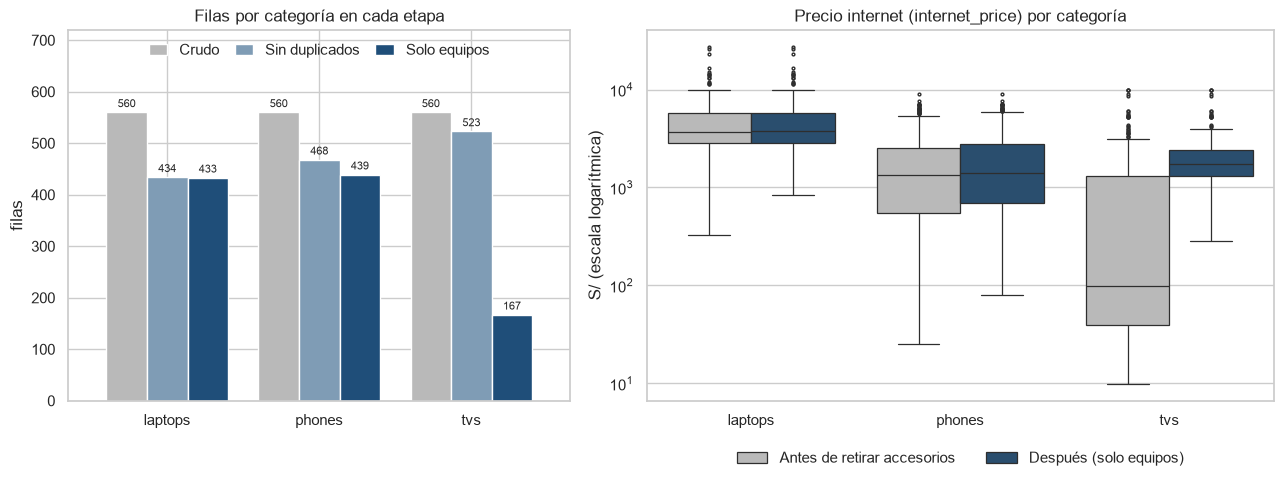

**Interpretación.** El efecto es enorme en `tvs`: la mediana de precio pasa de S/ 99 a S/ 1,729: con los accesorios, el "televisor típico" era un cable o un control; sin ellos queda en el rango real de un televisor. En `phones` (S/ 1,339 → S/ 1,399) y `laptops` (S/ 3,719 → S/ 3,739) el cambio es pequeño porque allí los accesorios eran pocos. Conclusión: sin este filtro, cualquier comparación de precios entre categorías habría sido engañosa.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw={"width_ratios": [1, 1.25]})

# Panel izquierdo: filas por categoría en cada etapa
etapas = pd.DataFrame({
    "Crudo": raw.category.value_counts(),
    "Sin duplicados": norm_sin_dup.category.value_counts(),
    "Solo equipos": conservadas.category.value_counts(),
}).loc[CATS]
etapas.plot.bar(ax=axes[0], color=["#b9b9b9", "#7f9cb5", "#1f4e79"], width=0.8, rot=0)
for cont in axes[0].containers:
    axes[0].bar_label(cont, fontsize=8, padding=2)
axes[0].set_title("Filas por categoría en cada etapa")
axes[0].set_xlabel("")
axes[0].set_ylabel("filas")
axes[0].set_ylim(0, 720)
axes[0].legend(title="", frameon=False, loc="upper center", ncol=3, columnspacing=1.0, handlelength=1.2)

# Panel derecho: precio antes vs. después (escala log)
antes = norm_sin_dup.assign(etapa="Antes de retirar accesorios")
despues = conservadas.assign(etapa="Después (solo equipos)")
datos = pd.concat([antes, despues])
sns.boxplot(data=datos, x="category", y="internet_price", hue="etapa", order=CATS, ax=axes[1],
            palette=["#b9b9b9", "#1f4e79"], fliersize=2, linewidth=0.9)
axes[1].set_yscale("log")
axes[1].set_title("Precio internet (internet_price) por categoría")
axes[1].set_xlabel("")
axes[1].set_ylabel("S/ (escala logarítmica)")
axes[1].legend(title="", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
savefig("pre_01_accesorios_antes_despues")
plt.show()

med_a = norm_sin_dup.groupby("category").internet_price.median()
med_d = conservadas.groupby("category").internet_price.median()
say(
    f"**Interpretación.** El efecto es enorme en `tvs`: la mediana de precio pasa de {soles(med_a['tvs'])} a "
    f"{soles(med_d['tvs'])}: con los accesorios, el \"televisor típico\" era un cable o un control; sin ellos "
    f"queda en el rango real de un televisor. En `phones` ({soles(med_a['phones'])} → {soles(med_d['phones'])}) y "
    f"`laptops` ({soles(med_a['laptops'])} → {soles(med_d['laptops'])}) el cambio es pequeño porque allí los accesorios "
    f"eran pocos. Conclusión: sin este filtro, cualquier comparación de precios entre categorías habría sido engañosa."
)

### 2.4 Marcas (`brand`)

**Problema.** `GENERICO` aparece en muchas filas y no es una marca real: es la etiqueta que usa la tienda cuando el vendedor no declara marca. El documento del grupo pide "normalizar y decidir qué hacer con GENERICO". La marca ya viene en mayúsculas desde el scraper; igualmente se normaliza en 2.2.

**Decisión.** **Conservar `GENERICO` como una categoría explícita**: no se imputa ni se elimina. Es una decisión que el grupo debe confirmar.

**Justificación.** Asignarle una marca a un producto sin marca sería inventar un dato; borrar esas filas quitaría productos válidos (por ejemplo, celulares básicos). Dejarlo como categoría explícita permite que quien analice marcas (Persona 4) decida si la excluye de un ranking.

In [11]:
tabla_gen = pd.DataFrame({
    "etapa": ["crudo (con duplicados)", "sin duplicados", "dataset final (solo equipos)"],
    "filas": [len(raw), len(norm_sin_dup), len(conservadas)],
    "filas GENERICO": [int((raw.brand.str.upper() == "GENERICO").sum()),
                       int((norm_sin_dup.brand == "GENERICO").sum()),
                       int((conservadas.brand == "GENERICO").sum())],
})
tabla_gen["% GENERICO"] = (tabla_gen["filas GENERICO"] / tabla_gen["filas"] * 100).round(1)
display(tabla_gen)

gen_final = conservadas[conservadas.brand == "GENERICO"]
display(gen_final.groupby("category").size().rename("filas GENERICO en el dataset final").to_frame().T)
display(conservadas.brand.value_counts().head(12).rename("filas").to_frame().T)
say(
    f"**Resultado.** `GENERICO` pasa de {tabla_gen.loc[0,'filas GENERICO']} filas en el crudo a **{tabla_gen.loc[2,'filas GENERICO']}** en el "
    f"dataset final ({tabla_gen.loc[2,'% GENERICO']} %): la mayoría de los `GENERICO` eran accesorios y salieron en 2.3. "
    f"Los que quedan son sobre todo celulares básicos de fabricantes pequeños."
)

,etapa,filas,filas GENERICO,% GENERICO
0,crudo (con duplicados),1680,238,14.2
1,sin duplicados,1425,214,15.0
2,dataset final (solo equipos),1039,11,1.1


category,phones,tvs
filas GENERICO en el dataset final,8,3


brand,LENOVO,SAMSUNG,APPLE,ASUS,HP,XIAOMI,HONOR,LG,MOTOROLA,TCL,ACER,ZTE
filas,154,134,122,109,96,82,64,59,26,25,17,15


**Resultado.** `GENERICO` pasa de 238 filas en el crudo a **11** en el dataset final (1.1 %): la mayoría de los `GENERICO` eran accesorios y salieron en 2.3. Los que quedan son sobre todo celulares básicos de fabricantes pequeños.

### 2.5 Valores faltantes: `list_price` y `cmr_price`

**Problema.** `list_price` está vacío en una parte de las filas.

**Hipótesis a contrastar.** Según el spider (`_extract_prices`), `list_price` sale del precio **tachado** de la tarjeta (`data-normal-price`). Si la tarjeta no muestra precio tachado, el campo queda vacío: o sea, **el producto no tiene descuento**. Si es cierto, los vacíos no son pérdida de información sino ausencia de rebaja, y el valor correcto de `list_price` es el precio que realmente se cobra, `internet_price`.

**Evidencia a revisar:** en las filas con `list_price`, ¿alguna vez el precio internet iguala o supera al de lista? Si nunca ocurre, un precio de lista presente siempre implica rebaja y un vacío implica ausencia de rebaja.

In [12]:
base = conservadas.copy()
con_lista = base.dropna(subset=["list_price"])
iguales = int((con_lista.internet_price == con_lista.list_price).sum())
mayores = int((con_lista.internet_price > con_lista.list_price).sum())
faltan = base.list_price.isna()
print(f"Con list_price: {len(con_lista)} filas | internet == list: {iguales} | internet > list: {mayores}")

por_cat_nulos = (base.assign(vacio=faltan).groupby("category").vacio.agg(["sum", "mean"])
                 .rename(columns={"sum": "vacíos", "mean": "% vacío"}).loc[CATS])
por_cat_nulos["% vacío"] = (por_cat_nulos["% vacío"] * 100).round(1)
display(por_cat_nulos)
say(
    f"**Hallazgo.** En las {len(con_lista)} filas con `list_price` el precio internet es **siempre menor** "
    f"({iguales} igualdades, {mayores} mayores): el scraper solo reporta precio de lista cuando hay rebaja. Eso respalda la hipótesis."
)

Con list_price: 1003 filas | internet == list: 0 | internet > list: 0


,vacíos,% vacío
category,,
laptops,16,3.7
phones,15,3.4
tvs,5,3.0


**Hallazgo.** En las 1003 filas con `list_price` el precio internet es **siempre menor** (0 igualdades, 0 mayores): el scraper solo reporta precio de lista cuando hay rebaja. Eso respalda la hipótesis.

**Decisión.** Imputar `list_price = internet_price` en las filas vacías y marcar cada una con `list_price_imputed = 1`.

**Justificación.** (1) Es el valor coherente con la fuente: precio de lista = precio vigente cuando no hay rebaja. (2) Evita borrar filas válidas, que habría sesgado el dataset hacia productos con descuento. (3) La bandera permite al análisis separar productos sin descuento y revertir la imputación si el grupo decide otro criterio. (4) Una imputación por media o mediana inventaría descuentos inexistentes.

**`cmr_price` no se imputa.** Su vacío significa "no hay precio CMR", que es información válida; rellenarlo con otro precio inventaría un descuento con tarjeta que no existe. Se comprueba que, cuando existe, es siempre menor al precio internet:

In [13]:
imp = pp.impute_list_price(base)
n_imp = int(imp.list_price_imputed.sum())
print("Nulos en list_price después:", int(imp.list_price.isna().sum()))
display(imp[imp.list_price_imputed == 1][["category", "product", "list_price", "internet_price", "list_price_imputed"]].head(5))

con_cmr = imp.dropna(subset=["cmr_price"])
cmr_mayor = int((con_cmr.cmr_price >= con_cmr.internet_price).sum())
pct_cmr = (imp.assign(tiene=imp.cmr_price.notna()).groupby("category").tiene.mean().loc[CATS] * 100).round(1)
tras = pd.DataFrame({"% nulos antes": (base.isna().mean() * 100).round(2), "% nulos después": (imp[base.columns].isna().mean() * 100).round(2)})
display(tras)
say(
    f"**Resultado.** Se imputan **{n_imp} filas** ({n_imp/len(imp):.1%}): "
    + ", ".join(f"`{c}` {int(imp[imp.category==c].list_price_imputed.sum())}" for c in CATS)
    + f". `list_price` ya no tiene nulos. `cmr_price` queda vacío en {int(imp.cmr_price.isna().sum())} filas "
    f"({imp.cmr_price.isna().mean():.1%}) por diseño; en las {len(con_cmr)} que lo tienen, nunca es mayor ni igual al precio internet "
    f"({cmr_mayor} casos). Porcentaje de publicaciones con precio CMR: "
    + ", ".join(f"`{c}` {pct_cmr[c]} %" for c in CATS) + "."
)

Nulos en list_price después: 0


,category,product,list_price,internet_price,list_price_imputed
11,phones,IPHONE 18 PRO 256GB BLACK,6899.0,6899.0,1
18,phones,IPHONE 17 256GB,4399.0,4399.0,1
77,phones,CELULAR MAGIC8 PRO 5G 12+512GB,3599.0,3599.0,1
117,phones,CELULAR G06 4+64GB,389.0,389.0,1
175,phones,X7C 8GB+256GB - FOREST GREEN,999.0,999.0,1


,% nulos antes,% nulos después
product,0.00,0.00
brand,0.00,0.00
category,0.00,0.00
seller,0.00,0.00
list_price,3.46,0.00
internet_price,0.00,0.00
cmr_price,82.48,82.48


**Resultado.** Se imputan **36 filas** (3.5%): `laptops` 16, `phones` 15, `tvs` 5. `list_price` ya no tiene nulos. `cmr_price` queda vacío en 857 filas (82.5%) por diseño; en las 182 que lo tienen, nunca es mayor ni igual al precio internet (0 casos). Porcentaje de publicaciones con precio CMR: `laptops` 13.9 %, `phones` 18.9 %, `tvs` 23.4 %.

### 2.6 Outliers de precio

**Problema.** Los precios son muy asimétricos: hay celulares básicos de S/ 80 y laptops de más de S/ 25,000 en el mismo dataset.

**Decisión.** Aplicar la **regla del IQR (factor 1.5) sobre `internet_price`, dentro de cada categoría y después de sacar los accesorios** (como indica el documento del grupo), y **marcar** los atípicos con `is_price_outlier = 1` en lugar de eliminarlos. Un precio es atípico si cae fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` de su categoría.

**Justificación.**
- *Dentro de cada categoría*: un precio de S/ 9,000 es normal en un televisor grande y raro en un celular.
- *Después de los accesorios*: si se calcula antes, los cables de S/ 10 deforman Q1 y el límite.
- *Marcar, no borrar*: el grupo acordó no eliminar datos solo por tener precio o descuento alto; si luego se quiere filtrar, debe sustentarse con una fuente externa. La bandera permite excluirlos en el análisis que lo requiera.

In [14]:
out = pp.flag_price_outliers(imp)
marcados = out[out.is_price_outlier == 1].sort_values(["category", "internet_price"])

q = out.groupby("category").internet_price.quantile([.25, .75]).unstack()
q.columns = ["Q1", "Q3"]
q["IQR"] = q["Q3"] - q["Q1"]
q["límite inferior"] = q["Q1"] - 1.5 * q["IQR"]
q["límite superior"] = q["Q3"] + 1.5 * q["IQR"]
q["atípicos"] = out.groupby("category").is_price_outlier.sum()
display(q.loc[CATS].round(0))
display(marcados[["category", "product", "list_price", "internet_price", "seller"]].tail(10))

,Q1,Q3,IQR,límite inferior,límite superior,atípicos
category,,,,,,
laptops,2859.0,5699.0,2840.0,-1401.0,9959.0,15
phones,699.0,2779.0,2080.0,-2421.0,5899.0,20
tvs,1299.0,2399.0,1100.0,-352.0,4050.0,18


,category,product,list_price,internet_price,seller
1153,tvs,"TELEVISOR 98"" QLED TV 98A400 4K ULTRA HD GOOGLE TV - 144 HZ",7999.0,5499.0,FALABELLA
1169,tvs,TELEVISOR 65'' OLED S90H VISION AI SMART TV (2026),6799.0,5499.0,FALABELLA
1159,tvs,TELEVISOR 98 CRYSTAL UHD DU9000 4K TIZEN OS SMART TV (2024),12999.0,5699.0,FALABELLA
1165,tvs,TELEVISOR 98'' 4K UHD UN98U9500HGXPE VISION AI SMART TV - MODELO NUEVO,11999.0,5989.0,SEVEN SHOP
1170,tvs,TELEVISOR 85'' NEO QLED QN70H VISION AI SMART TV (2026),6599.0,5999.0,FALABELLA
1151,tvs,TELEVISOR 75'' MICRO RGB R95H VISION AI SMART TV (2026),11999.0,8599.0,FALABELLA
1184,tvs,"TELEVISOR 65"" OLED S95F VISION AI SMART TV (2025)",10599.0,8999.0,FALABELLA
1195,tvs,"TELEVISOR 77"" OLED EVO AI C6 4K SMART TV 2026",12999.0,9999.0,FALABELLA
1237,tvs,"TELEVISOR 100"" QNED EVO MINILED AI 4K SMART TV 2026 100QNED85BS",12999.0,9999.0,FALABELLA
1336,tvs,TELEVISOR QLED 98 UHD 4K SMART TV 98C655,15999.0,9999.0,TECNHOGAR MYK


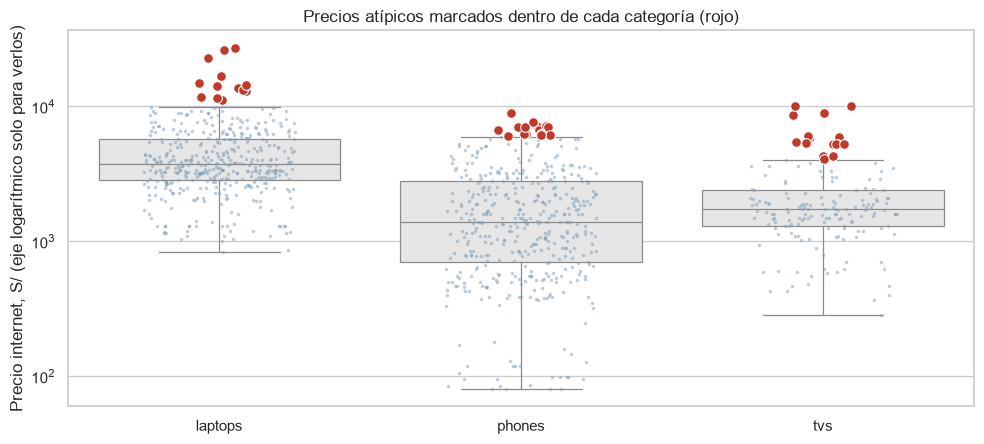

**Interpretación.** Se marcan **53 filas** (5.1%): 15 en `laptops`, 20 en `phones` y 18 en `tvs`. Todas son precios **altos**: como los precios tienen cola larga a la derecha, el IQR marca sobre todo la gama más alta de cada categoría (laptops sobre S/ 9,959, celulares sobre S/ 5,899, televisores sobre S/ 4,050). Son productos reales (por ejemplo una laptop de S/ 27,346), no errores de captura, así que se **conservan marcados**; quien necesite quitarlos solo filtra `is_price_outlier == 0`.

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.boxplot(data=out, x="category", y="internet_price", order=CATS, color="#e6e6e6", fliersize=0, linewidth=0.9, ax=ax)
sns.stripplot(data=out[out.is_price_outlier == 0], x="category", y="internet_price", order=CATS,
              color="#7f9cb5", size=2.5, alpha=0.5, jitter=0.25, ax=ax)
sns.stripplot(data=out[out.is_price_outlier == 1], x="category", y="internet_price", order=CATS,
              color="#c0392b", size=7, edgecolor="white", linewidth=0.8, jitter=0.1, ax=ax)
ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("Precio internet, S/ (eje logarítmico solo para verlos)")
ax.set_title("Precios atípicos marcados dentro de cada categoría (rojo)")
plt.tight_layout()
savefig("pre_02_outliers_precio")
plt.show()

por_cat = out.groupby("category").is_price_outlier.sum()
n_alto = int((marcados.internet_price > marcados.category.map(q["límite superior"])).sum())
n_bajo = len(marcados) - n_alto
say(
    f"**Interpretación.** Se marcan **{len(marcados)} filas** ({len(marcados)/len(out):.1%}): "
    f"{por_cat['laptops']} en `laptops`, {por_cat['phones']} en `phones` y {por_cat['tvs']} en `tvs`. "
    f"{'Todas son precios **altos**' if n_bajo == 0 else f'{n_alto} son precios **altos** y {n_bajo} bajos'}: como los precios tienen cola larga a la derecha, "
    f"el IQR marca sobre todo la gama más alta de cada categoría (laptops sobre {soles(q.loc['laptops','límite superior'])}, "
    f"celulares sobre {soles(q.loc['phones','límite superior'])}, televisores sobre {soles(q.loc['tvs','límite superior'])}). "
    f"Son productos reales (por ejemplo una laptop de {soles(out.internet_price.max())}), "
    f"no errores de captura, así que se **conservan marcados**; quien necesite quitarlos solo filtra `is_price_outlier == 0`."
)

**Observación para quien analice descuentos (no se corrige aquí).** Revisando `list_price` contra `internet_price` aparecen descuentos implícitos muy grandes. Una parte son errores evidentes de digitación del vendedor en el precio de lista, que inflan el descuento. Este notebook no los modifica: el documento del grupo deja el análisis de "descuentos inflados" a Personas 3 y 4.

In [16]:
desc = 1 - out.internet_price / out.list_price
grandes = out[desc > 0.7].assign(descuento=(desc[desc > 0.7] * 100).round(1)).sort_values("list_price", ascending=False)
display(grandes[["category", "product", "list_price", "internet_price", "descuento", "seller"]].head(8))
say(f"**Lectura.** {len(grandes)} {'fila' if len(grandes) == 1 else 'filas'} del dataset limpio {'tiene' if len(grandes) == 1 else 'tienen'} un descuento implícito mayor a 70 %; "
    f"el caso más extremo tiene un precio de lista de {soles(out.list_price.max())} contra un precio internet de "
    f"{soles(out.loc[out.list_price.idxmax(), 'internet_price'])}. Se dejan tal cual y se reportan a Personas 3 y 4.")

,category,product,list_price,internet_price,descuento,seller
1023,laptops,"LAPTOP LOQ 15AHP10 AMD RYZEN 7 250 16GB DDR5 512GB RTX 5050 8GB 15.6"" FHD 14...",79999.0,5699.0,92.9,IVANCE ELECTRONIC ONLINE


**Lectura.** 1 fila del dataset limpio tiene un descuento implícito mayor a 70 %; el caso más extremo tiene un precio de lista de S/ 79,999 contra un precio internet de S/ 5,699. Se dejan tal cual y se reportan a Personas 3 y 4.

## 3. Integración

La Parte II trabaja con **una sola fuente**: el CSV que produjo el spider de Falabella en una sola captura (`data/raw/falabella_raw.csv`). No hay tablas que unir ni claves que cruzar, por lo que la integración se reduce a **comprobar la consistencia del esquema** y a documentar lo que no se integró:

- La base de Supabase del scraper diario (`SUPABASE_DB_URL`) puede tener más capturas; **no se usa** en esta etapa y esa decisión se documenta en la propuesta de pipeline (Persona 1). El dataset es, por tanto, una **foto en un solo momento**: no permite analizar evolución de precios.
- Ripley fue descartado en la Parte I (spider eliminado), así que no hay segunda tienda que integrar.

In [17]:
esperadas = ["product", "brand", "category", "seller", "list_price", "internet_price", "cmr_price"]
assert list(raw.columns) == esperadas, "El esquema del CSV crudo cambió"
assert set(raw.category.unique()) == set(CATS), "Categorías inesperadas"
assert (raw.internet_price > 0).all()
assert (raw.cmr_price.dropna() < raw.internet_price[raw.cmr_price.notna()]).all()
print("Esquema, categorías, precios positivos y cmr_price menor al precio internet: OK")

Esquema, categorías, precios positivos y cmr_price menor al precio internet: OK


## 4. Reducción

In [18]:
say(
    f"- **Reducción de filas (numerosidad):** se pasa de {N_RAW:,} a {len(out):,} filas al quitar duplicados y productos que no son el equipo. "
    f"Es una reducción *con propósito*: cada fila retirada se justificó y quedó auditada.\n"
    f"- **Reducción de columnas:** **no se elimina ninguna**. Las 7 columnas originales son todas necesarias para los objetivos (precio, descuento, "
    f"marca, vendedor y categoría), y con solo 3 variables numéricas no hay base para reducir dimensionalidad con PCA u otra técnica.\n"
    f"- **Muestreo:** no se aplica; el dataset ya es pequeño y submuestrear solo perdería casos."
)

- **Reducción de filas (numerosidad):** se pasa de 1,680 a 1,039 filas al quitar duplicados y productos que no son el equipo. Es una reducción *con propósito*: cada fila retirada se justificó y quedó auditada.
- **Reducción de columnas:** **no se elimina ninguna**. Las 7 columnas originales son todas necesarias para los objetivos (precio, descuento, marca, vendedor y categoría), y con solo 3 variables numéricas no hay base para reducir dimensionalidad con PCA u otra técnica.
- **Muestreo:** no se aplica; el dataset ya es pequeño y submuestrear solo perdería casos.

## 5. Transformación y tipos de dato

- `category` → tipo `category` (3 valores). Precios (`list_price`, `internet_price`, `cmr_price`) → `float64`. `list_price_imputed` e `is_price_outlier` → enteros de 8 bits (0/1).
- `product`, `brand` y `seller` ya quedaron en texto normalizado (sección 2.2).
- **No se escalan ni se codifican variables**: el escalado y la codificación pertenecen al modelado, que esta parte no incluye. Las variables derivadas (descuento, gama, tipo de vendedor, etc.) las construye la Persona 3.
- Los precios se conservan en soles, sin transformarlos. La tabla de tipos antes y después está al final de la sección 6.

## 6. Resultado final y trazabilidad

Se ejecuta el pipeline completo (`pp.run()`), que guarda `data/clean/falabella_cleaned.csv` y `data/clean/falabella_removed_rows.csv`. Se verifica que el resultado coincide con el paso a paso de las secciones anteriores.

In [19]:
clean, removed, log = pp.run()
display(log)

# Verificación cruzada: el paso a paso del notebook == pipeline completo
ref = pp.cast_types(out).reset_index(drop=True)
pd.testing.assert_frame_equal(clean, ref, check_dtype=False)
print(f"OK: el notebook y pipeline/cleaning.py producen el mismo dataset ({clean.shape[0]} filas x {clean.shape[1]} columnas)")

,paso,filas_antes,filas_despues,filas_afectadas
0,duplicados exactos,1680,1426,254
1,duplicados tras normalizar texto,1426,1425,1
2,accesorios y productos que no son el equipo,1425,1039,386
3,list_price vacio imputado con internet_price,1039,1039,36
4,precios atipicos marcados (no eliminados),1039,1039,53


OK: el notebook y pipeline/cleaning.py producen el mismo dataset (1039 filas x 9 columnas)


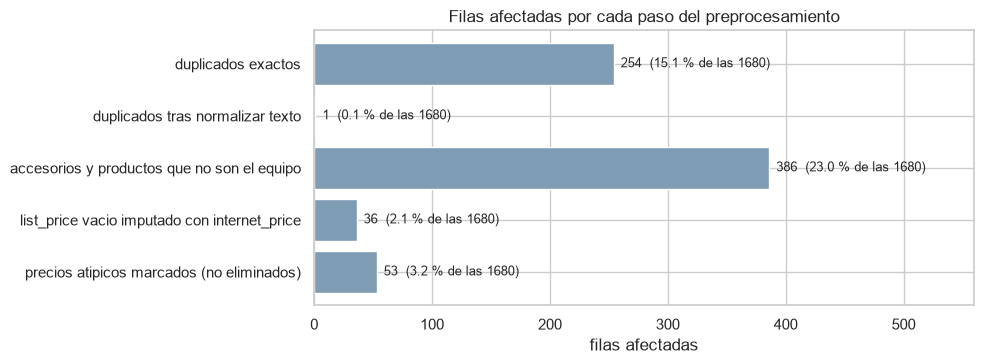

**Interpretación.** Dos pasos explican casi todo el cambio: quitar accesorios (386 filas) y duplicados exactos (254). Los otros dos pasos no eliminan filas: la imputación de `list_price` modifica 36 y los atípicos solo se marcan (53). El dataset final conserva el 61.8% de las filas crudas.

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.8))
orden = log.assign(pct=log.filas_afectadas / N_RAW * 100)
colores = ["#7f9cb5"] * len(orden)
ax.barh(orden.paso[::-1], orden.filas_afectadas[::-1], color=colores[::-1])
for y, (v, p) in enumerate(zip(orden.filas_afectadas[::-1], orden.pct[::-1])):
    ax.text(v + 6, y, f"{v}  ({p:.1f} % de las {N_RAW})", va="center", fontsize=9)
ax.set_xlim(0, orden.filas_afectadas.max() * 1.45)
ax.set_xlabel("filas afectadas")
ax.set_title("Filas afectadas por cada paso del preprocesamiento")
plt.tight_layout()
savefig("pre_03_filas_afectadas_por_paso")
plt.show()
say(
    f"**Interpretación.** Dos pasos explican casi todo el cambio: quitar accesorios ({int(log.filas_afectadas[2])} filas) y "
    f"duplicados exactos ({int(log.filas_afectadas[0])}). Los otros dos pasos no eliminan filas: la imputación de "
    f"`list_price` modifica {int(log.filas_afectadas[3])} y los atípicos solo se marcan ({int(log.filas_afectadas[4])}). "
    f"El dataset final conserva el {len(clean)/N_RAW:.1%} de las filas crudas."
)

In [21]:
antes = raw.groupby("category").agg(filas=("product", "size"), mediana_precio=("internet_price", "median"),
                                    pct_con_cmr=("cmr_price", lambda s: s.notna().mean()))
despues = clean.groupby("category", observed=True).agg(filas=("product", "size"), mediana_precio=("internet_price", "median"),
                                                       pct_con_cmr=("cmr_price", lambda s: s.notna().mean()))
comparacion = pd.concat({"crudo": antes, "limpio": despues}, axis=1).loc[CATS]
comparacion[("crudo", "pct_con_cmr")] = (comparacion[("crudo", "pct_con_cmr")] * 100).round(1)
comparacion[("limpio", "pct_con_cmr")] = (comparacion[("limpio", "pct_con_cmr")] * 100).round(1)
display(comparacion)

print("Tipos de dato antes (crudo) y después (limpio):")
tipos = pd.concat([raw.dtypes.astype(str).rename("antes (crudo)"),
                   clean.dtypes.astype(str).rename("después (limpio)")], axis=1).fillna("(columna nueva)")
display(tipos)

resumen = pd.DataFrame({
    "tipo": clean.dtypes.astype(str),
    "nulos": clean.isna().sum(),
    "distintos": clean.nunique(),
    "mínimo": clean.min(numeric_only=True),
    "máximo": clean.max(numeric_only=True),
})
display(resumen)

crudo                            limpio                           
         filas mediana_precio pct_con_cmr  filas mediana_precio pct_con_cmr
category                                                                   
laptops    560       3789.500        12.1    433         3739.0        13.9
phones     560       1224.000        15.7    439         1399.0        18.9
tvs        560         98.985        12.7    167         1729.0        23.4

Tipos de dato antes (crudo) y después (limpio):


,antes (crudo),después (limpio)
product,str,str
brand,str,str
category,str,category
seller,str,str
list_price,float64,float64
internet_price,float64,float64
cmr_price,float64,float64
list_price_imputed,(columna nueva),int8
is_price_outlier,(columna nueva),int8


,tipo,nulos,distintos,mínimo,máximo
brand,str,0,40,NaN,NaN
category,category,0,3,NaN,NaN
cmr_price,float64,857,121,299.0,13499.00
internet_price,float64,0,461,79.9,27345.56
is_price_outlier,int8,0,2,0.0,1.00
list_price,float64,0,318,159.0,79999.00
list_price_imputed,int8,0,2,0.0,1.00
product,str,0,931,NaN,NaN
seller,str,0,186,NaN,NaN


In [22]:
n_tv = int((clean.category == "tvs").sum())
n_gen = int((clean.brand == "GENERICO").sum())
say(f"""### Limitaciones del dataset final

1. **Una sola captura y una sola tienda.** Es una foto de Falabella Perú en un momento; no permite medir evolución de precios ni comparar con otros retailers.
2. **Muestra de 20 páginas por categoría.** El scraper recorrió las primeras 20 páginas del listado (el orden lo define la tienda), así que no es una muestra aleatoria del catálogo.
3. **Filtro de accesorios basado en reglas.** Está validado manualmente sobre las filas de borde (secciones 2.3a y 2.3b), pero no es infalible; las filas retiradas se guardan con su motivo.
4. **`tvs` queda con pocas filas** ({n_tv}): cualquier segmentación fina por marca o gama dentro de televisores tendrá celdas pequeñas.
5. **Publicaciones con mismo producto y vendedor** y distinto precio se conservaron; pueden ser variantes o errores de captura y el CSV no permite distinguirlos.
6. **`list_price` imputado** en {n_imp} filas (bandera `list_price_imputed`): el supuesto "sin precio tachado = sin descuento" proviene del código del spider, no de una verificación en la tienda.
7. **`cmr_price` vacío** en {int(clean.cmr_price.isna().sum())} filas porque no hay precio CMR; no se imputa. Quien calcule el ahorro con tarjeta debe trabajar solo con las filas que sí lo tienen.
8. **`GENERICO` y otras etiquetas sin marca real** ({n_gen} filas) se conservaron sin modificar; quien analice marcas debe decidir si las excluye.
9. **Errores de digitación en `list_price`** (descuentos de más de 70 %) se reportan en 2.6 pero no se corrigen.""")

### Limitaciones del dataset final

1. **Una sola captura y una sola tienda.** Es una foto de Falabella Perú en un momento; no permite medir evolución de precios ni comparar con otros retailers.
2. **Muestra de 20 páginas por categoría.** El scraper recorrió las primeras 20 páginas del listado (el orden lo define la tienda), así que no es una muestra aleatoria del catálogo.
3. **Filtro de accesorios basado en reglas.** Está validado manualmente sobre las filas de borde (secciones 2.3a y 2.3b), pero no es infalible; las filas retiradas se guardan con su motivo.
4. **`tvs` queda con pocas filas** (167): cualquier segmentación fina por marca o gama dentro de televisores tendrá celdas pequeñas.
5. **Publicaciones con mismo producto y vendedor** y distinto precio se conservaron; pueden ser variantes o errores de captura y el CSV no permite distinguirlos.
6. **`list_price` imputado** en 36 filas (bandera `list_price_imputed`): el supuesto "sin precio tachado = sin descuento" proviene del código del spider, no de una verificación en la tienda.
7. **`cmr_price` vacío** en 857 filas porque no hay precio CMR; no se imputa. Quien calcule el ahorro con tarjeta debe trabajar solo con las filas que sí lo tienen.
8. **`GENERICO` y otras etiquetas sin marca real** (11 filas) se conservaron sin modificar; quien analice marcas debe decidir si las excluye.
9. **Errores de digitación en `list_price`** (descuentos de más de 70 %) se reportan en 2.6 pero no se corrigen.